# Phase 0 — Feasibility test

**Goal.** Before collecting anything, check that enough repositories adopted agent skills *after* the format
appeared (October 2025) **and** already had agent-authored pull requests before adopting them.

**Steps** (from `CLAUDE.md`):
1. Join GitSkills and AIDev on `owner/repo` (case-normalised).
2. Keep repositories whose first `SKILL.md` was committed in October 2025 or later; measure how many candidate
   repositories have **no adoption date** (GitSkills only dates one representative per distinct content).
3. Keep repositories with at least 5 agent PRs before adoption.
4. Produce a funnel table (repositories left after each filter), separately for AIDev-pop and full AIDev.

**Decision rule.** At least ~100 usable adopting repositories → continue to Phase 1. Otherwise fall back to the
skill-removal study.

**Dataset versions.** `CLAUDE.md` describes AIDev v3 (cutoff 1 Aug 2025). The current release on Hugging Face is
**v5 (cutoff 31 Mar 2026)**, which already contains part of the "after" period. Both versions are analysed here,
pinned to exact commits.

Re-running this notebook is safe: raw extracts are downloaded once into `data/raw/` and reused.

## 0. Configuration

In [1]:
from pathlib import Path
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
from huggingface_hub import HfApi

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
RAW, INTERIM, PROCESSED, FIG = (ROOT / "data" / "raw", ROOT / "data" / "interim",
                                ROOT / "data" / "processed", ROOT / "figures")
for d in (RAW, INTERIM, PROCESSED, FIG):
    d.mkdir(parents=True, exist_ok=True)

# Pinned dataset revisions (Hugging Face commit hashes) for reproducibility.
GITSKILLS_REPO, GITSKILLS_REV = "mvaccargiu/gitskills", "ebab17454a7c236f8f26b183567f1a126f42e3f8"
AIDEV_REPO = "hao-li/AIDev"
AIDEV_REV = {"v3": "3ca0045773097b138b064550dfd6e72229f40bee",   # tag v3, ~0.9M PRs
             "v5": "b37f9fd1613cfec55886105bb76721918d015dc7"}   # tag v5, 7.6M PRs

FORMAT_START = "2025-10-01"   # agent skills format introduced in October 2025
MIN_PRE_PRS = 5               # minimum agent PRs before adoption
DECISION_THRESHOLD = 100      # usable adopting repositories needed to continue
STD_LOCATIONS = ("canonical", "skills-dir")   # GitSkills location classes kept as "real" skills
SCOPES = [("v3", "pop"), ("v3", "all"), ("v5", "pop"), ("v5", "all")]

con = duckdb.connect()
con.execute("INSTALL httpfs; LOAD httpfs;")

def hf_url(repo, rev, path):
    return f"https://huggingface.co/datasets/{repo}/resolve/{rev}/{path}"

def ts(col):
    # ISO-8601 strings ending in 'Z' -> naive UTC timestamps
    return f"TRY_CAST(replace({col}, 'Z', '') AS TIMESTAMP)"

q = lambda sql: con.execute(sql).df()

## 1. Inspect the real schemas

Read only the Parquet footers (no data download) so that no column name is assumed.

In [2]:
api = HfApi()
gs_files = {t: sorted(f for f in api.list_repo_files(GITSKILLS_REPO, repo_type="dataset", revision=GITSKILLS_REV)
                      if f.startswith(f"data/{t}/") and f.endswith(".parquet"))
            for t in ("artifacts", "repos")}
print({t: len(v) for t, v in gs_files.items()}, "parquet parts")

AIDEV_TABLES = {"all": ("all_pull_request", "all_repository"), "pop": ("pull_request", "repository")}

def schema(url):
    s = q(f"SELECT name, type FROM parquet_schema('{url}') WHERE name <> 'schema'")
    rows = q(f"SELECT sum(row_group_num_rows) AS n FROM (SELECT DISTINCT row_group_id, row_group_num_rows "
             f"FROM parquet_metadata('{url}'))").n[0]
    return s, int(rows)

schemas = {}
for t, files in gs_files.items():
    schemas[f"gitskills/{t}"] = schema(hf_url(GITSKILLS_REPO, GITSKILLS_REV, files[0]))
for ver, rev in AIDEV_REV.items():
    for tables in AIDEV_TABLES.values():
        for t in tables:
            schemas[f"aidev_{ver}/{t}"] = schema(hf_url(AIDEV_REPO, rev, f"{t}.parquet"))

for name, (s, n) in schemas.items():
    print(f"{name:32s} rows={n:>10,}  " + ", ".join(s.name))

{'artifacts': 31, 'repos': 1} parquet parts


gitskills/artifacts              rows=   525,954  repo_full_name, path, filename, location_class, file_sha, discovered_at, content, content_fetched, frontmatter_valid, name, description, body_chars, history_fetched, composition_fetched, dedup_primary, first_commit_at, last_commit_at, commit_count, sibling_count, sibling_bytes, has_scripts, has_references, content_sha_ok, composition_truncated, first_commit_author, first_commit_author_type, first_commit_message, last_commit_author, last_commit_author_type, last_commit_message
gitskills/repos                  rows=   282,200  full_name, owner, stars, forks, is_fork, language, license, description, created_at, pushed_at, metadata_fetched
aidev_v3/all_pull_request        rows=   932,791  id, number, title, body, agent, user_id, user, state, created_at, closed_at, merged_at, repo_id, repo_url, html_url
aidev_v3/all_repository          rows=   116,211  id, url, license, full_name, language, forks, stars
aidev_v3/pull_request            rows=

## 2. Download light raw extracts (once)

Only the columns needed for the feasibility test are pulled (DuckDB reads just those column chunks over HTTP).
Personal fields (logins, titles, bodies, commit messages) are **not** downloaded at this stage.

In [3]:
def extract(name, sql):
    out = RAW / f"{name}.parquet"
    if out.exists():
        return out
    tmp = out.with_suffix(".tmp")
    con.execute(f"COPY ({sql}) TO '{tmp}' (FORMAT parquet, COMPRESSION zstd)")
    tmp.rename(out)  # atomic: an interrupted download never leaves a half-written file
    return out

gs_art_urls = [hf_url(GITSKILLS_REPO, GITSKILLS_REV, f) for f in gs_files["artifacts"]]
gs_repo_urls = [hf_url(GITSKILLS_REPO, GITSKILLS_REV, f) for f in gs_files["repos"]]

extract("gitskills_artifacts_light", f'''
    SELECT repo_full_name, path, filename, location_class, file_sha, dedup_primary, history_fetched,
           first_commit_at, last_commit_at, commit_count, first_commit_author_type,
           frontmatter_valid, has_scripts, has_references
    FROM read_parquet({gs_art_urls})''')
extract("gitskills_repos", f'''
    SELECT full_name, stars, forks, is_fork, language, created_at, pushed_at
    FROM read_parquet({gs_repo_urls})''')

for ver, rev in AIDEV_REV.items():
    for scope, (pr_t, repo_t) in AIDEV_TABLES.items():
        extract(f"aidev_{ver}_{scope}_pr", f'''
            SELECT id, agent, state, created_at, closed_at, merged_at, repo_id, repo_url
            FROM read_parquet('{hf_url(AIDEV_REPO, rev, pr_t + ".parquet")}')''')
        extract(f"aidev_{ver}_{scope}_repo", f"SELECT * FROM read_parquet('{hf_url(AIDEV_REPO, rev, repo_t + '.parquet')}')")

sorted((p.name, round(p.stat().st_size / 1e6, 1)) for p in RAW.glob("*.parquet"))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

[('aidev_v3_all_pr.parquet', 23.6),
 ('aidev_v3_all_repo.parquet', 3.9),
 ('aidev_v3_pop_pr.parquet', 0.7),
 ('aidev_v3_pop_repo.parquet', 0.1),
 ('aidev_v5_all_pr.parquet', 203.2),
 ('aidev_v5_all_repo.parquet', 36.2),
 ('aidev_v5_pop_pr.parquet', 7.8),
 ('aidev_v5_pop_repo.parquet', 0.9),
 ('gitskills_artifacts_light.parquet', 125.6),
 ('gitskills_repos.parquet', 7.8)]

## 3. Load and sanity-check

In [4]:
con.execute(f'''
CREATE OR REPLACE VIEW skills AS
SELECT *, lower(repo_full_name) AS repo, {ts('first_commit_at')} AS first_ts,
       filename = 'SKILL.md' AS exact_name,
       location_class IN {STD_LOCATIONS} AS std_location
FROM read_parquet('{RAW}/gitskills_artifacts_light.parquet')''')
con.execute(f'''
CREATE OR REPLACE VIEW gs_repos AS
SELECT *, lower(full_name) AS repo FROM read_parquet('{RAW}/gitskills_repos.parquet')''')

for ver, scope in SCOPES:
    con.execute(f'''
    CREATE OR REPLACE VIEW pr_{ver}_{scope} AS
    SELECT id, agent, state, repo_url,
           lower(regexp_replace(repo_url, '^https://api\\.github\\.com/repos/', '')) AS repo,
           {ts('created_at')} AS created_ts, merged_at IS NOT NULL AS merged
    FROM read_parquet('{RAW}/aidev_{ver}_{scope}_pr.parquet')''')

# AIDev: size, period covered, and repo key format
pd.concat([q(f'''
    SELECT '{v}/{s}' AS scope, count(*) AS prs, count(DISTINCT repo) AS repos,
           min(created_ts) AS first_pr, max(created_ts) AS last_pr,
           count(*) FILTER (WHERE repo_url NOT LIKE 'https://api.github.com/repos/%') AS bad_repo_url,
           count(*) FILTER (WHERE created_ts IS NULL) AS bad_dates
    FROM pr_{v}_{s}''') for v, s in SCOPES])

,scope,prs,repos,first_pr,last_pr,bad_repo_url,bad_dates
0,v3/pop,33596,2807,2024-12-24 00:23:09,2025-07-30 19:36:13,0,0
0,v3/all,932791,116423,2024-12-24 00:23:09,2025-07-30 19:50:49,0,0
0,v5/pop,361296,25403,2024-12-24 00:23:09,2026-03-31 23:58:42,0,0
0,v5/all,7685281,961165,2024-12-24 00:23:09,2026-03-31 23:59:59,0,0


In [5]:
# PRs per agent and period, per AIDev scope
pd.concat([q(f'''
    SELECT '{v}/{s}' AS scope, agent, count(*) AS prs,
           count(*) FILTER (WHERE created_ts >= TIMESTAMP '{FORMAT_START}') AS prs_after_format_start,
           round(avg(merged::INT), 3) AS merge_rate
    FROM pr_{v}_{s} GROUP BY agent ORDER BY prs DESC''') for v, s in SCOPES])

,scope,agent,prs,prs_after_format_start,merge_rate
0,v3/pop,OpenAI_Codex,21799,0,0.826
1,v3/pop,Copilot,4970,0,0.430
2,v3/pop,Devin,4827,0,0.538
3,v3/pop,Cursor,1541,0,0.652
4,v3/pop,Claude_Code,459,0,0.590
0,v3/all,OpenAI_Codex,814522,0,0.877
1,v3/all,Copilot,50447,0,0.591
2,v3/all,Cursor,32941,0,0.705
3,v3/all,Devin,29744,0,0.644
4,v3/all,Claude_Code,5137,0,0.768


In [6]:
# GitSkills: which files carry a commit history (and therefore a date)?
q('''
SELECT location_class, exact_name, dedup_primary, history_fetched,
       count(*) AS files, count(first_ts) AS dated
FROM skills GROUP BY ALL ORDER BY files DESC''')

,location_class,exact_name,dedup_primary,history_fetched,files,dated
0,skills-dir,True,0,0,1059294,0
1,skills-dir,True,1,0,910545,0
2,other,True,0,0,741862,0
3,other,True,1,0,480260,0
4,canonical,True,1,1,268366,268366
5,skills-dir,True,1,1,120287,120287
6,canonical,True,0,0,98667,0
7,other,True,1,1,61980,61980
8,other,False,1,0,21568,0
9,other,False,0,0,13109,0


In [7]:
# What do the location classes look like? (most frequent folder patterns)
q('''
SELECT * FROM (
    SELECT location_class, regexp_replace(path, '/[^/]+/[^/]+$', '/<skill>/<file>') AS pattern,
           count(*) AS files
    FROM skills GROUP BY location_class, pattern)
QUALIFY row_number() OVER (PARTITION BY location_class ORDER BY files DESC) <= 6
ORDER BY location_class, files DESC''')

,location_class,pattern,files
0,canonical,.claude/skills/<skill>/<file>,317316
1,canonical,claude/.claude/skills/<skill>/<file>,2006
2,canonical,project-template/.claude/skills/<skill>/<file>,1478
3,canonical,main/.claude/skills/<skill>/<file>,1159
4,canonical,templates/.claude/skills/<skill>/<file>,802
5,canonical,agent-system/.claude/skills/<skill>/<file>,767
6,other,data/<skill>/<file>,56189
7,other,development/<skill>/<file>,39092
8,other,skill-flow/data/skills-refined-agentskillos-36...,29012
9,other,SKILL.md,28023


In [8]:
# Case-normalisation: does lower(owner/repo) ever merge two distinct GitSkills repositories?
q('''SELECT count(*) AS collisions FROM (SELECT repo FROM gs_repos GROUP BY repo HAVING count(DISTINCT full_name) > 1)''')

,collisions
0,9


## 4. Adoption date per repository

* A **skill** = file named exactly `SKILL.md` in a standard location (`canonical` or `skills-dir`).
  Lower-case `skill.md` and files in other places are ignored: they are often unrelated notes or pre-format files.
* **Adoption date** = earliest `first_commit_at` among the repository's dated skills.
* GitSkills dates only a representative copy of each distinct content, so a repository can have
  * `complete` dates (all its skills dated) → adoption date is exact (on the default branch);
  * `partial` dates → the date is an **upper bound** (an undated copy may be older); to verify via the GitHub API;
  * `missing` dates → adoption date unknown; recoverable via the GitHub API (path history of the `SKILL.md`).

In [9]:
con.execute(f'''
CREATE OR REPLACE TABLE repo_adoption AS
WITH any_file AS (SELECT repo, count(*) AS n_files_any FROM skills GROUP BY repo),
std AS (
    SELECT repo, count(*) AS n_skills, count(first_ts) AS n_dated, min(first_ts) AS adoption_ts,
           bool_or(has_scripts = 1) AS any_scripts
    FROM skills WHERE exact_name AND std_location GROUP BY repo)
SELECT a.repo, a.n_files_any, coalesce(s.n_skills, 0) AS n_skills, coalesce(s.n_dated, 0) AS n_dated,
       s.adoption_ts,
       CASE WHEN s.n_skills IS NULL THEN 'no_std_skill'
            WHEN s.n_dated = 0 THEN 'missing'
            WHEN s.n_dated < s.n_skills THEN 'partial'
            ELSE 'complete' END AS date_status,
       r.is_fork, r.stars
FROM any_file a LEFT JOIN std s USING (repo) LEFT JOIN gs_repos r USING (repo)''')

adopt = q("SELECT * FROM repo_adoption")
adopt.to_parquet(INTERIM / "repo_adoption.parquet", index=False)
q('''SELECT date_status, count(*) AS repos,
            count(*) FILTER (WHERE adoption_ts < TIMESTAMP '2025-10-01') AS dated_before_format
     FROM repo_adoption GROUP BY 1 ORDER BY 2 DESC''')

,date_status,repos,dated_before_format
0,missing,119621,0
1,no_std_skill,62095,0
2,partial,54003,12
3,complete,46481,13


## 5. Agent PRs per repository, before and after adoption

For AIDev v3 every PR predates October 2025, so all PRs of an October-2025+ adopter are "before".
For AIDev v5 (cutoff 31 Mar 2026) PRs are split at each repository's own adoption date.
For undated repositories, PRs created before October 2025 are a safe lower bound of their "before" PRs.

In [10]:
counts = {}
for v, s in SCOPES:
    counts[(v, s)] = q(f'''
    SELECT p.repo, count(*) AS n_pr,
           count(*) FILTER (WHERE p.created_ts < TIMESTAMP '{FORMAT_START}') AS n_before_format,
           count(*) FILTER (WHERE p.created_ts <  a.adoption_ts) AS n_pre_adopt,
           count(*) FILTER (WHERE p.created_ts >= a.adoption_ts) AS n_post_adopt
    FROM pr_{v}_{s} p LEFT JOIN repo_adoption a USING (repo) GROUP BY p.repo''')

## 6. Funnel

In [11]:
STEPS = [
    "AIDev repositories (>= 1 agent PR)",
    "... found in GitSkills (any skill-like file)",
    "... with >= 1 SKILL.md in a standard location",
    "... with a known adoption date (complete or partial)",
    f"... first SKILL.md on/after {FORMAT_START}",
    f"... >= {MIN_PRE_PRS} agent PRs before adoption  [USABLE ADOPTERS]",
    "    of which: adoption date complete (exact)",
    "    of which: not a fork",
    f"    of which: >= {MIN_PRE_PRS} agent PRs after adoption already in AIDev",
    f"Undated SKILL.md repos with >= {MIN_PRE_PRS} PRs before {FORMAT_START} (recoverable via API, upper bound)",
    f"Never-treated controls: not in GitSkills, >= {MIN_PRE_PRS} PRs before {FORMAT_START}",
]
fmt = pd.Timestamp(FORMAT_START)

def funnel(c):
    m = c.merge(adopt, on="repo", how="left")
    s1 = m[m.n_files_any.notna()]
    s2 = s1[s1.n_skills > 0]
    s3 = s2[s2.date_status.isin(["complete", "partial"])]
    s4 = s3[s3.adoption_ts >= fmt]
    s5 = s4[s4.n_pre_adopt >= MIN_PRE_PRS]
    undated = s2[(s2.date_status == "missing") & (s2.n_before_format >= MIN_PRE_PRS)]
    controls = m[m.n_files_any.isna() & (m.n_before_format >= MIN_PRE_PRS)]
    n = [len(m), len(s1), len(s2), len(s3), len(s4), len(s5),
         int((s5.date_status == "complete").sum()), int((s5.is_fork == 0).sum()),
         int((s5.n_post_adopt >= MIN_PRE_PRS).sum()), len(undated), len(controls)]
    return pd.Series(n, index=STEPS), s5

results = {f"{v}/{s}": funnel(counts[(v, s)]) for v, s in SCOPES}
funnel_tbl = pd.DataFrame({k: r[0] for k, r in results.items()})
funnel_tbl.columns = pd.MultiIndex.from_tuples(
    [(f"AIDev {k.split('/')[0]}", "AIDev-pop" if k.endswith("pop") else "AIDev (all)") for k in funnel_tbl.columns])
funnel_tbl.to_csv(PROCESSED / "phase0_funnel.csv")
pd.concat({k: r[1] for k, r in results.items()}, names=["scope"]).reset_index(level=0) \
  .to_parquet(INTERIM / "phase0_usable_adopters.parquet", index=False)
funnel_tbl

AIDev v3              \
                                                   AIDev-pop AIDev (all)   
AIDev repositories (>= 1 agent PR)                      2807      116423   
... found in GitSkills (any skill-like file)             523        1414   
... with >= 1 SKILL.md in a standard location            491        1320   
... with a known adoption date (complete or par...       243         752   
... first SKILL.md on/after 2025-10-01                   243         752   
... >= 5 agent PRs before adoption  [USABLE ADO...       118         292   
    of which: adoption date complete (exact)              39         131   
    of which: not a fork                                 118         292   
    of which: >= 5 agent PRs after adoption alr...         0           0   
Undated SKILL.md repos with >= 5 PRs before 202...        94         219   
Never-treated controls: not in GitSkills, >= 5 ...       510       28100   

                                                    AIDev v5              
                                                   AIDev-pop AIDev (all)  
AIDev repositories (>= 1 agent PR)                     25403      961165  
... found in GitSkills (any skill-like file)            4073       27313  
... with >= 1 SKILL.md in a standard location           3675       24432  
... with a known adoption date (complete or par...      1867       14086  
... first SKILL.md on/after 2025-10-01                  1866       14083  
... >= 5 agent PRs before adoption  [USABLE ADO...       929        5136  
    of which: adoption date complete (exact)             423        2540  
    of which: not a fork                                 929        5135  
    of which: >= 5 agent PRs after adoption alr...       267        1502  
Undated SKILL.md repos with >= 5 PRs before 202...       262         635  
Never-treated controls: not in GitSkills, >= 5 ...      1494       59542

## 7. Figures

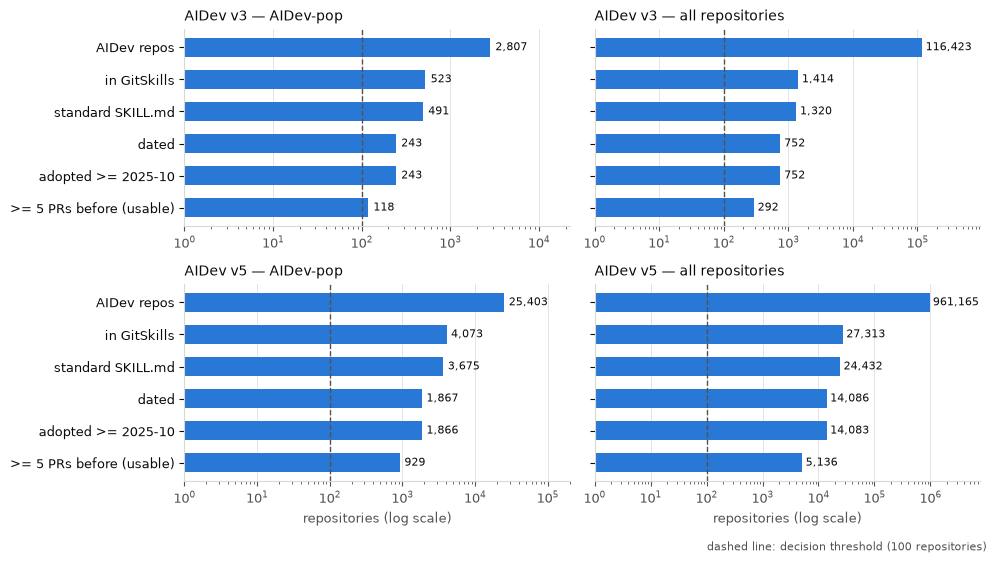

In [12]:
BLUE, INK, MUTED, GRID = "#2a78d6", "#0b0b0b", "#52514e", "#d9d8d4"
plt.rcParams.update({"font.size": 9, "axes.edgecolor": GRID, "axes.labelcolor": MUTED,
                     "xtick.color": MUTED, "ytick.color": INK, "axes.spines.top": False,
                     "axes.spines.right": False})

short = ["AIDev repos", "in GitSkills", "standard SKILL.md", "dated", f"adopted >= {FORMAT_START[:7]}",
         f">= {MIN_PRE_PRS} PRs before (usable)"]
fig, axes = plt.subplots(2, 2, figsize=(10, 5.6), sharey=True)
for ax, (key, (series, _)) in zip(axes.flat, results.items()):
    vals = series.iloc[:6].values
    y = range(len(vals))[::-1]
    ax.barh(list(y), vals, color=BLUE, height=0.6)
    ax.set_xscale("log")
    ax.set_xlim(1, max(vals) * 8)
    ax.axvline(DECISION_THRESHOLD, color=MUTED, lw=1, ls="--")
    for yi, v in zip(y, vals):
        ax.text(max(v, 1) * 1.15, yi, f"{v:,}", va="center", color=INK, fontsize=8)
    ax.set_yticks(list(y), short)
    v_, s_ = key.split("/")
    ax.set_title(f"AIDev {v_} — {'AIDev-pop' if s_ == 'pop' else 'all repositories'}", loc="left",
                 color=INK, fontsize=10)
    ax.grid(axis="x", color=GRID, lw=0.5)
    ax.set_axisbelow(True)
axes[1, 0].set_xlabel("repositories (log scale)"); axes[1, 1].set_xlabel("repositories (log scale)")
fig.text(0.99, 0.01, f"dashed line: decision threshold ({DECISION_THRESHOLD} repositories)",
         ha="right", color=MUTED, fontsize=8)
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(FIG / "phase0_funnel.png", dpi=200)
plt.show()

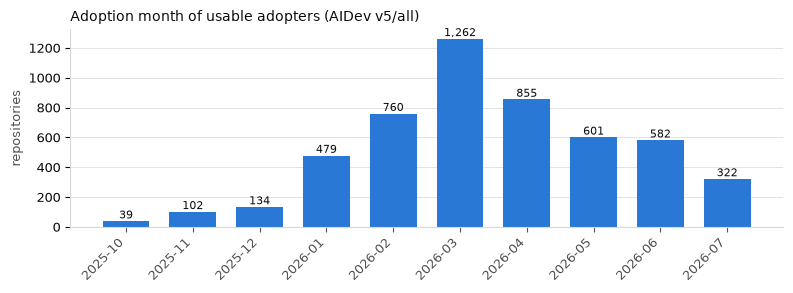

In [13]:
# When did the usable adopters adopt skills? (largest scope)
best = max(results, key=lambda k: len(results[k][1]))
usable = results[best][1]
months = usable.adoption_ts.dt.to_period("M").value_counts().sort_index()
fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(months.index.astype(str), months.values, color=BLUE, width=0.7)
for i, v in enumerate(months.values):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=8, color=INK)
ax.set_title(f"Adoption month of usable adopters (AIDev {best})", loc="left", color=INK, fontsize=10)
ax.set_ylabel("repositories")
ax.grid(axis="y", color=GRID, lw=0.5); ax.set_axisbelow(True)
plt.xticks(rotation=45, ha="right")
fig.tight_layout()
fig.savefig(FIG / "phase0_adoption_months.png", dpi=200)
plt.show()

## 8. Decision

In [14]:
usable_row = STEPS[5]
for col in funnel_tbl.columns:
    n = funnel_tbl.loc[usable_row, col]
    verdict = "GO (>= threshold)" if n >= DECISION_THRESHOLD else "BELOW threshold"
    print(f"{' / '.join(col):28s} usable adopters = {n:>6,}  ->  {verdict}")

AIDev v3 / AIDev-pop         usable adopters =    118  ->  GO (>= threshold)
AIDev v3 / AIDev (all)       usable adopters =    292  ->  GO (>= threshold)
AIDev v5 / AIDev-pop         usable adopters =    929  ->  GO (>= threshold)
AIDev v5 / AIDev (all)       usable adopters =  5,136  ->  GO (>= threshold)


## 9. Caveats to carry into Phase 1

* **Adoption dates come from the default branch only** (GitSkills, July 2026 snapshot). A skill added and later
  removed before July 2026 is invisible; a "never-treated" control may have adopted skills after July 2026, or have
  skills outside the code-search index (GitSkills is a lower bound). → Either stop the analysis window in July 2026,
  or re-check controls through the GitHub API.
* **Partial and missing dates** must be completed through the GitHub API (commit history of each `SKILL.md` path)
  before the panel is built; the funnel shows how many repositories this affects.
* **AIDev version.** v5 already covers October 2025 → March 2026 with the same identification queries, so the main
  analysis window ends on 31 March 2026 and needs no new PR collection. An optional extension to April → July 2026
  must reuse the v5 identification queries (documented in the AIDev dataset card).
* Reviews, timeline and merger information exist only for AIDev-pop; outside it they must come from the GitHub API.